In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Load official NASA test data
test_df = pd.read_csv(
    root / "data/raw/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

# Load official true RUL values
rul_df = pd.read_csv(
    root / "data/raw/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["true_RUL"]
)

# Get the last available cycle for each test engine
test_end = (
    test_df.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)

# Verify official RUL labels align with engine IDs
assert len(test_end) == len(rul_df) == 100
assert np.array_equal(
    test_end["engine_id"].to_numpy(),
    np.arange(1, 101)
)

test_end["true_RUL"] = rul_df["true_RUL"].to_numpy()

print("=== OFFICIAL NASA TEST DATA ===")
print("Total sensor records:", len(test_df))
print("Test engines:", test_df["engine_id"].nunique())
print("RUL labels:", len(rul_df))
print("Missing values:", test_df.isnull().sum().sum())

print("\n=== LAST OBSERVED CYCLE PER ENGINE ===")
display(test_end[["engine_id", "cycle", "true_RUL"]].head(10))

print("\n=== TRUE RUL STATISTICS ===")
display(test_end["true_RUL"].describe())

# Save endpoint labels
test_end[["engine_id", "cycle", "true_RUL"]].to_csv(
    root / "data/processed/test_endpoints.csv",
    index=False
)

print("\nOfficial test endpoints prepared!")


=== OFFICIAL NASA TEST DATA ===
Total sensor records: 13096
Test engines: 100
RUL labels: 100
Missing values: 0

=== LAST OBSERVED CYCLE PER ENGINE ===


,engine_id,cycle,true_RUL
0,1,31,112
1,2,49,98
2,3,126,69
3,4,106,82
4,5,98,91
5,6,105,93
6,7,160,91
7,8,166,95
8,9,55,111
9,10,192,96



=== TRUE RUL STATISTICS ===


count    100.00000
mean      75.52000
std       41.76497
min        7.00000
25%       32.75000
50%       86.00000
75%      112.25000
max      145.00000
Name: true_RUL, dtype: float64


Official test endpoints prepared!


In [2]:

import json
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load saved XGBoost model
xgb_model = XGBRegressor()
xgb_model.load_model(str(root / "models/xgboost_fd001.json"))

# Load required features
with open(root / "models/xgboost_features.json") as f:
    feature_cols = json.load(f)

selected_sensors = [
    f"sensor_{i}"
    for i in range(1, 22)
    if f"sensor_{i}_latest" in feature_cols
]

print("XGBoost model loaded!")
print("Input features:", len(feature_cols))
print("Selected sensors:", len(selected_sensors))


XGBoost model loaded!
Input features: 61
Selected sensors: 15


In [3]:

WINDOW = 30

def create_test_features(data, sensors):
    data = data.sort_values(
        ["engine_id", "cycle"]
    ).reset_index(drop=True)

    grouped = data.groupby("engine_id")

    features = data[["engine_id", "cycle"]].copy()

    for sensor in sensors:
        group_sensor = grouped[sensor]

        features[f"{sensor}_latest"] = data[sensor]

        features[f"{sensor}_mean30"] = group_sensor.transform(
            lambda x: x.rolling(
                WINDOW, min_periods=WINDOW
            ).mean()
        )

        features[f"{sensor}_std30"] = group_sensor.transform(
            lambda x: x.rolling(
                WINDOW, min_periods=WINDOW
            ).std()
        )

        features[f"{sensor}_delta30"] = (
            data[sensor] - group_sensor.shift(WINDOW - 1)
        )

    # Use only the last available cycle for each engine
    features = (
        features.groupby("engine_id")
        .tail(1)
        .sort_values("engine_id")
        .reset_index(drop=True)
    )

    return features


test_features = create_test_features(
    test_df, selected_sensors
)

assert len(test_features) == 100
assert not test_features[feature_cols].isna().any().any()
assert np.array_equal(
    test_features["engine_id"],
    test_end["engine_id"]
)

print("=== TEST FEATURES READY ===")
print("Test shape:", test_features.shape)
print("Input features:", len(feature_cols))
print("Engines:", len(test_features))


=== TEST FEATURES READY ===
Test shape: (100, 62)
Input features: 61
Engines: 100


In [4]:

# Generate predictions
X_test = test_features[feature_cols]

y_true = test_end["true_RUL"].to_numpy()

y_pred = np.maximum(
    0, xgb_model.predict(X_test)
)

# Overall metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

errors = y_pred - y_true

print("=== OFFICIAL NASA XGBOOST RESULTS ===")
print(f"MAE: {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")
print(f"Overestimation: {(errors > 0).mean()*100:.2f}%")

# Near-failure evaluation
near_mask = y_true <= 30
near_errors = errors[near_mask]

print("\n=== NEAR-FAILURE RESULTS ===")
print("Engines:", near_mask.sum())
print(
    "Near-failure MAE:",
    round(mean_absolute_error(
        y_true[near_mask], y_pred[near_mask]
    ), 2)
)
print(
    "Overestimation:",
    round((near_errors > 0).mean() * 100, 2), "%"
)
print("Large overestimates (20+):", (near_errors >= 20).sum())

# Save individual predictions
results = test_end[
    ["engine_id", "cycle", "true_RUL"]
].copy()

results["predicted_RUL"] = y_pred
results["error"] = errors

results.to_csv(
    root / "data/processed/xgboost_official_predictions.csv",
    index=False
)

print("\n=== SAMPLE TEST PREDICTIONS ===")
display(results.head(10).round(2))


=== OFFICIAL NASA XGBOOST RESULTS ===
MAE: 18.04 cycles
RMSE: 26.49 cycles
Overestimation: 63.00%

=== NEAR-FAILURE RESULTS ===
Engines: 25
Near-failure MAE: 4.1
Overestimation: 56.0 %
Large overestimates (20+): 0

=== SAMPLE TEST PREDICTIONS ===


,engine_id,cycle,true_RUL,predicted_RUL,error
0,1,31,112,174.429993,62.43
1,2,49,98,162.509995,64.51
2,3,126,69,56.639999,-12.36
3,4,106,82,88.150002,6.15
4,5,98,91,92.430000,1.43
5,6,105,93,124.440002,31.44
6,7,160,91,87.860001,-3.14
7,8,166,95,102.269997,7.27
8,9,55,111,167.970001,56.97
9,10,192,96,81.370003,-14.63


In [5]:

import torch
import torch.nn as nn
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class RUL_LSTM(nn.Module):
    def __init__(self, input_size=15, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :]).squeeze(-1)


# Load best saved LSTM checkpoint
checkpoint = torch.load(
    root / "models/lstm_fd001.pt",
    map_location=device,
    weights_only=True
)

lstm_model = RUL_LSTM(
    input_size=checkpoint["input_size"]
).to(device)

lstm_model.load_state_dict(checkpoint["model_state"])
lstm_model.eval()

# Retrieve original training preprocessing
sensors = checkpoint["sensor_names"]
window = checkpoint["window"]
rul_scale = checkpoint["rul_scale"]

scaler_mean = np.array(checkpoint["scaler_mean"])
scaler_scale = np.array(checkpoint["scaler_scale"])

print("=== LSTM LOADED ===")
print("Device:", device)
print("Sensors:", len(sensors))
print("Window size:", window)
print("Model loaded successfully!")


=== LSTM LOADED ===
Device: cpu
Sensors: 15
Window size: 30
Model loaded successfully!


In [6]:

# Prepare 30-cycle sequences for all 100 engines

X_test_lstm = []
engine_ids = []

for engine_id, engine in test_df.groupby("engine_id"):

    engine = engine.sort_values("cycle")

    assert len(engine) >= window, (
        f"Engine {engine_id} has insufficient history"
    )

    # Extract last 30 cycles
    values = engine[sensors].tail(window).to_numpy(
        dtype=np.float32
    )

    # Normalize with TRAINING statistics only
    values = (
        (values - scaler_mean) / scaler_scale
    ).astype(np.float32)

    X_test_lstm.append(values)
    engine_ids.append(engine_id)

X_test_lstm = np.stack(X_test_lstm)

assert X_test_lstm.shape == (100, 30, 15)
assert np.array_equal(
    np.array(engine_ids),
    test_end["engine_id"].to_numpy()
)

print("=== LSTM TEST DATA ===")
print("Shape:", X_test_lstm.shape)
print("Engines:", len(engine_ids))
print("Ready for prediction!")


=== LSTM TEST DATA ===
Shape: (100, 30, 15)
Engines: 100
Ready for prediction!


In [7]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate predictions
X_tensor = torch.tensor(
    X_test_lstm,
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    lstm_pred = (
        lstm_model(X_tensor).cpu().numpy() * rul_scale
    )

lstm_pred = np.maximum(0, lstm_pred)

y_true = test_end["true_RUL"].to_numpy()

# Compare raw LSTM and previously selected 5-cycle buffer
results = []

for buffer in [0, 5]:

    adjusted = np.maximum(0, lstm_pred - buffer)
    errors = adjusted - y_true

    near_mask = y_true <= 30
    near_errors = errors[near_mask]

    results.append({
        "Model": f"LSTM + {buffer} buffer",
        "MAE": mean_absolute_error(y_true, adjusted),
        "RMSE": np.sqrt(mean_squared_error(y_true, adjusted)),
        "Overestimation %": (errors > 0).mean() * 100,
        "Near Failure MAE": mean_absolute_error(
            y_true[near_mask], adjusted[near_mask]
        ),
        "Near Overestimation %": (
            near_errors > 0
        ).mean() * 100,
        "Large Overestimates (20+)": int(
            (near_errors >= 20).sum()
        )
    })

lstm_test_results = pd.DataFrame(results)

print("=== OFFICIAL NASA LSTM RESULTS ===")
display(lstm_test_results.round(2))

# Save predictions
lstm_output = test_end[
    ["engine_id", "cycle", "true_RUL"]
].copy()

lstm_output["predicted_RUL"] = lstm_pred
lstm_output["predicted_RUL_buffer5"] = np.maximum(
    0, lstm_pred - 5
)

lstm_output.to_csv(
    root / "data/processed/lstm_official_predictions.csv",
    index=False
)

print("\nOfficial LSTM predictions saved!")


=== OFFICIAL NASA LSTM RESULTS ===


,Model,MAE,RMSE,Overestimation %,Near Failure MAE,Near Overestimation %,Large Overestimates (20+)
0,LSTM + 0 buffer,17.69,28.20,74.0,5.07,88.0,0
1,LSTM + 5 buffer,16.04,26.62,55.0,2.82,48.0,0



Official LSTM predictions saved!


=== 10 WORST LSTM PREDICTIONS ===


,engine_id,true_RUL,lstm_final,lstm_error,absolute_error
66,67,77,231.13,154.13,154.13
82,83,137,223.49,86.49,86.49
54,55,137,203.95,66.95,66.95
74,75,113,169.61,56.61,56.61
22,23,113,165.57,52.57,52.57
64,65,128,178.17,50.17,50.17
77,78,107,155.90,48.90,48.90
18,19,87,125.52,38.52,38.52
92,93,85,46.59,-38.41,38.41
0,1,112,149.14,37.14,37.14



=== ERROR ANALYSIS ===
Worst absolute error: 154.13
Engines with error > 30 cycles: 17


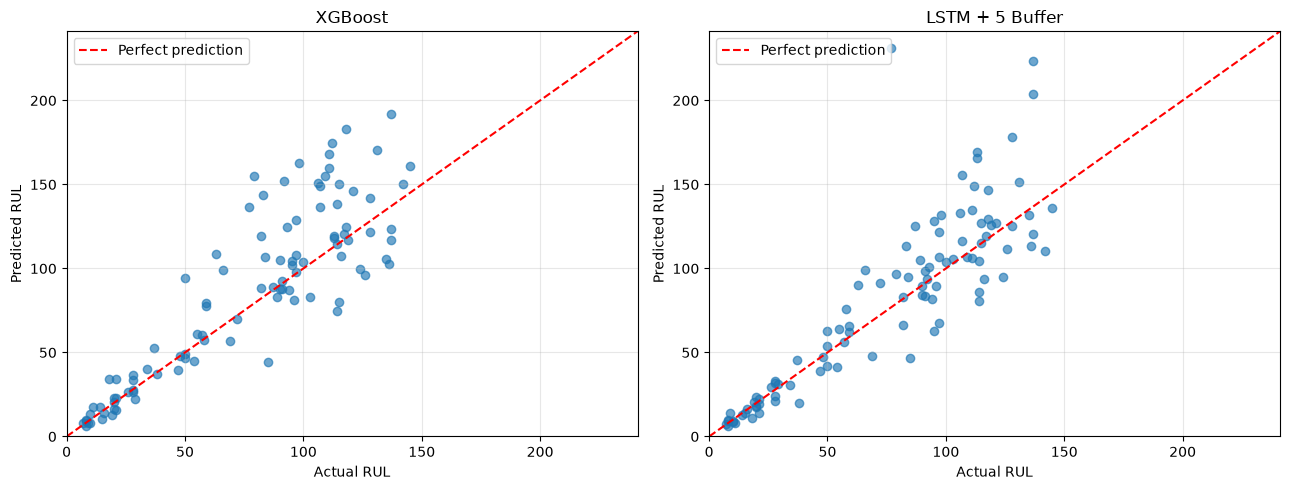

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load predictions from both models
xgb_results = pd.read_csv(
    root / "data/processed/xgboost_official_predictions.csv"
)

lstm_results = pd.read_csv(
    root / "data/processed/lstm_official_predictions.csv"
)

# Combine predictions for the same engines
comparison = lstm_results.merge(
    xgb_results[["engine_id", "true_RUL", "predicted_RUL"]],
    on=["engine_id", "true_RUL"],
    how="inner",
    validate="one_to_one",
    suffixes=("_lstm", "_xgb")
)

assert len(comparison) == 100

comparison["lstm_final"] = comparison["predicted_RUL_buffer5"]

comparison["lstm_error"] = (
    comparison["lstm_final"] - comparison["true_RUL"]
)

comparison["absolute_error"] = comparison["lstm_error"].abs()

# Find worst predictions
worst = comparison.sort_values(
    "absolute_error", ascending=False
).head(10)

print("=== 10 WORST LSTM PREDICTIONS ===")

display(
    worst[
        ["engine_id", "true_RUL", "lstm_final",
         "lstm_error", "absolute_error"]
    ].round(2)
)

print("\n=== ERROR ANALYSIS ===")
print("Worst absolute error:",
      round(comparison["absolute_error"].max(), 2))

print("Engines with error > 30 cycles:",
      (comparison["absolute_error"] > 30).sum())

# Compare predicted versus actual RUL
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("predicted_RUL_xgb", "XGBoost"),
    ("lstm_final", "LSTM + 5 Buffer")
]

limit = max(
    comparison["true_RUL"].max(),
    comparison["predicted_RUL_xgb"].max(),
    comparison["lstm_final"].max()
) + 10

for ax, (column, title) in zip(axes, models):
    ax.scatter(
        comparison["true_RUL"],
        comparison[column],
        alpha=0.65
    )

    ax.plot(
        [0, limit],
        [0, limit],
        "r--",
        label="Perfect prediction"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_title(title)
    ax.set_xlabel("Actual RUL")
    ax.set_ylabel("Predicted RUL")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

output_path = root / "outputs/figures/official_model_comparison.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=150)
plt.show()
